# Predict Phone Addiction: Exploratory Data Analysis
**Kaggle Playground Series S6E8.** Binary classification of `addicted_label`, scored by ROC-AUC.

This notebook explores the data before any modeling (see `modeling.ipynb` for the models). It has three parts:

1. **Data overview:** size, schema, missing values and the raw distribution of every feature.
2. **Visual EDA:** each feature against the target, feature-to-feature relationships and a train/test drift check.
   Every subsection ends with a **Takeaway** box stating what it means for modeling.
3. **Actionable conclusions:** a table of findings and the modeling actions they lead to.

### Setup

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold

# palette: class identity + neutral inks
C0, C1 = "#2a78d6", "#eb6834"          # not addicted / addicted
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#a3a29c", "#e4e3df"
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", ["#184f95", "#6da7ec", "#f0efec", "#ec7a79", "#a32a2a"])

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.axisbelow": True, "axes.labelsize": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "legend.frameon": False, "legend.fontsize": 8, "lines.linewidth": 2,
})

def prior_line(ax, orient="h"):
    """Dashed reference line at the overall addiction rate."""
    (ax.axhline if orient == "h" else ax.axvline)(prior, color=INK2, ls="--", lw=1, zorder=1)

In [2]:
TARGET = "addicted_label"
train_data = pd.read_csv("playground-series-s6e8/train.csv", index_col=0)
test_data = pd.read_csv("playground-series-s6e8/test.csv", index_col=0)

y = train_data[TARGET]
X = train_data.drop(columns=[TARGET])
num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = [c for c in X.columns if c not in num_cols]
prior = y.mean()

print(f"train: {len(train_data):,} rows × {X.shape[1]} features + target")
print(f"test:  {len(test_data):,} rows × {test_data.shape[1]} features")
print(f"numeric: {len(num_cols)}   categorical: {len(cat_cols)}   duplicated train rows: {train_data.duplicated().sum()}")

train: 691,369 rows × 12 features + target
test:  296,302 rows × 12 features
numeric: 9   categorical: 3   duplicated train rows: 0


---
## 1. Data overview

### 1.1 First rows

In [3]:
train_data.head()

,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,addicted_label
id,,,,,,,,,,,,,
0,24.0,NaN,1.83,1.59,2.11,7.46,122.0,38.0,8.63,Male,Medium,No,1
1,19.0,5.97,1.08,NaN,3.03,8.22,76.0,19.0,NaN,Female,Medium,No,0
2,18.0,5.09,NaN,NaN,NaN,6.25,134.0,60.0,7.47,Female,Low,Yes,0
3,21.0,6.42,1.26,1.42,3.36,8.85,112.0,94.0,8.66,Other,Low,NaN,1
4,26.0,11.20,1.87,2.81,1.95,5.25,NaN,NaN,13.39,Female,Medium,No,1


### 1.2 Schema: type, cardinality and missing values

In [4]:
schema = pd.DataFrame({
    "type": ["numeric" if c in num_cols else "categorical" for c in X.columns],
    "unique values": X.nunique(),
    "% missing (train)": X.isna().mean() * 100,
    "% missing (test)": test_data[X.columns].isna().mean() * 100,
})
schema.round(1)

,type,unique values,% missing (train),% missing (test)
age,numeric,18,4.2,5.8
daily_screen_time_hours,numeric,1389,13.9,11.1
social_media_hours,numeric,721,19.4,16.0
gaming_hours,numeric,401,18.3,20.1
work_study_hours,numeric,600,7.5,9.4
sleep_hours,numeric,451,6.4,7.6
notifications_per_day,numeric,231,9.8,11.5
app_opens_per_day,numeric,166,11.7,8.7
weekend_screen_time,numeric,1437,16.2,17.1
gender,categorical,3,4.2,4.8


### 1.3 Numeric summary

In [5]:
X[num_cols].describe().T.drop(columns="count").round(2)

,mean,std,min,25%,50%,75%,max
age,26.62,5.15,18.00,22.00,27.00,31.00,35.00
daily_screen_time_hours,7.64,2.72,0.50,5.48,7.77,9.84,15.00
social_media_hours,2.47,1.32,0.00,1.45,2.31,3.37,8.00
gaming_hours,1.46,0.93,0.00,0.70,1.33,2.09,4.00
work_study_hours,2.37,1.26,0.00,1.36,2.20,3.20,6.00
sleep_hours,6.80,1.23,4.50,5.78,6.80,7.87,9.00
notifications_per_day,145.89,65.92,20.00,93.00,150.00,204.00,250.00
app_opens_per_day,102.64,48.09,15.00,64.00,104.00,145.00,180.00
weekend_screen_time,9.48,2.86,0.51,7.28,9.58,11.75,17.56


### 1.4 Numeric distributions

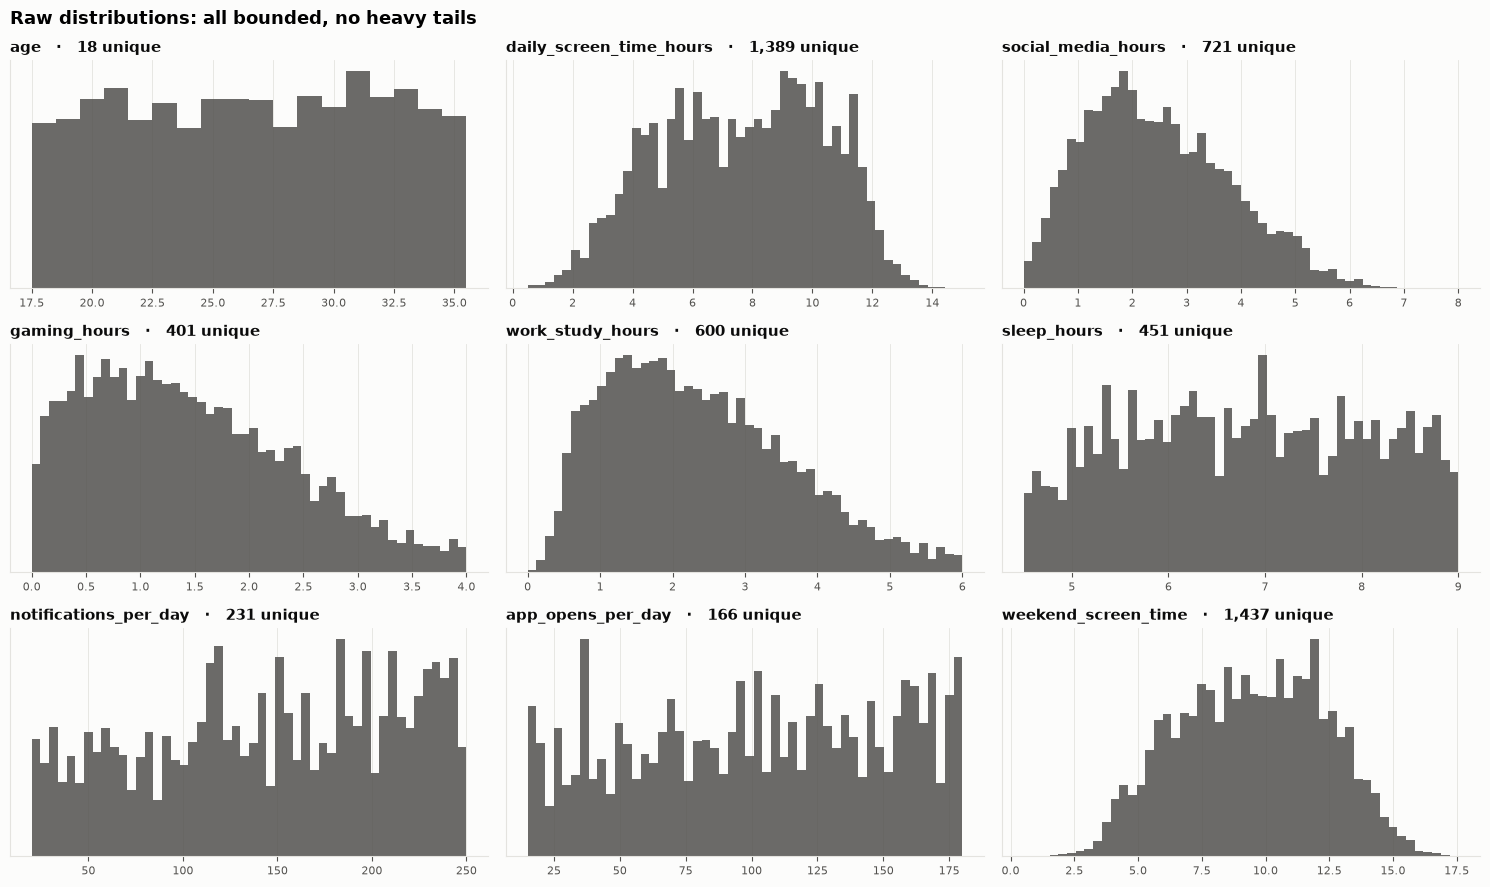

In [6]:
fig, axes = plt.subplots(3, 3, figsize=(15, 9))
for ax, c in zip(axes.flat, num_cols):
    v = X[c].dropna()
    bins = np.arange(v.min() - 0.5, v.max() + 1) if c == "age" else 50
    ax.hist(v, bins=bins, color=INK2, alpha=0.85)
    ax.set_title(f"{c}   ·   {v.nunique():,} unique", loc="left")
    ax.set_yticks([])
    ax.grid(axis="y", visible=False)
fig.suptitle("Raw distributions: all bounded, no heavy tails", x=0.01, ha="left", fontsize=13, weight="bold")
plt.tight_layout(); plt.show()

### 1.5 Categorical levels

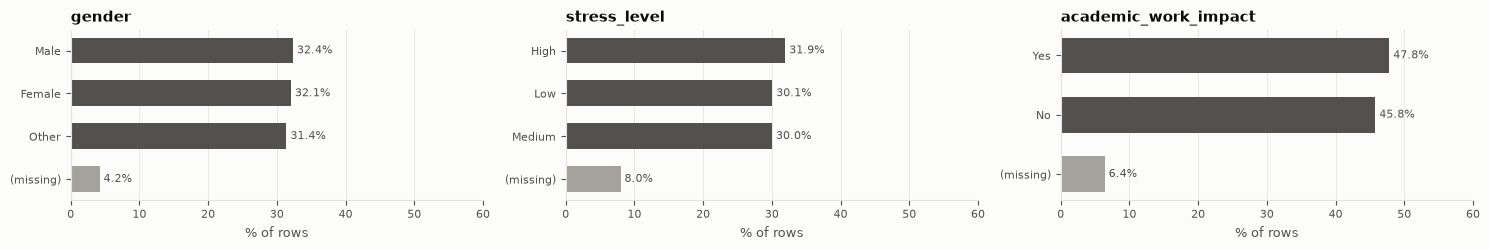

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 2.6))
for ax, c in zip(axes, cat_cols):
    share = X[c].fillna("(missing)").value_counts(normalize=True).sort_values()
    colors = [MUTED if k == "(missing)" else INK2 for k in share.index]
    ax.barh(share.index, share.values * 100, color=colors, height=0.6)
    for i, v in enumerate(share.values):
        ax.text(v * 100, i, f" {v:.1%}", va="center", fontsize=8, color=INK2)
    ax.set_xlim(0, 60)
    ax.set_xlabel("% of rows")
    ax.set_title(c, loc="left")
    ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

> **Takeaway: data overview.**
> * **691k training rows and 296k test rows**, 12 features: 9 numeric and 3 low-cardinality categoricals. No duplicated rows.
> * **Every feature has missing values** (4–19% per column, 61% of rows have at least one gap). Section 2.2 checks whether that carries signal.
> * `age`, `notifications_per_day` and `app_opens_per_day` are **integers with few distinct values** (18, 231 and 166).
>   The hour features are 2-decimal values with a few hundred to ~1,400 distinct values. Low cardinality makes it
>   practical to treat numeric columns as categories, which section 2.4 shows matters.
> * All numeric features are **bounded with no heavy tails** (e.g. screen time 0.5–15 h, notifications 20–250, sleep 4.5–9 h).
>   Only the social/gaming/work hours are mildly right-skewed, so no log transform or outlier clipping is needed.
> * The categoricals are **almost perfectly balanced** across their levels (≈ 1/3 each, or ≈ 1/2 for `academic_work_impact`),
>   which already hints they were generated independently of everything else.

---
## 2. Visual EDA: every feature vs the target

Same color code throughout: **blue = not addicted (0)**, **orange = addicted (1)**.
Each section ends with a **Takeaway** box giving the action it implies for modeling.

### 2.1 Target balance

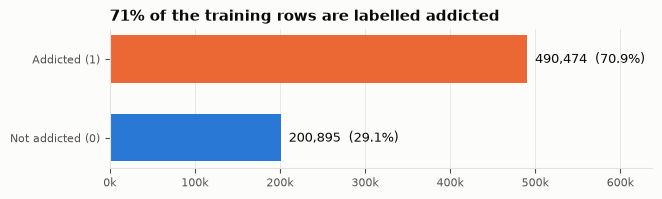

In [8]:
counts = y.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 1.8))
ax.barh(["Not addicted (0)", "Addicted (1)"], counts.values, color=[C0, C1], height=0.6)
for i, v in enumerate(counts.values):
    ax.text(v, i, f"  {v:,}  ({v / len(y):.1%})", va="center", color=INK, fontsize=9)
ax.set_xlim(0, counts.max() * 1.3)
ax.xaxis.set_major_formatter(lambda v, _: f"{v / 1e3:.0f}k")
ax.grid(axis="y", visible=False)
ax.set_title("71% of the training rows are labelled addicted", loc="left")
plt.show()

> **Takeaway: target.** The classes are moderately imbalanced (71 / 29). The submission is a
> probability, so rank-based **ROC-AUC** is the metric to optimise. Use **StratifiedKFold**.
> No resampling is needed, and the predictions should not be calibrated toward 50%.

### 2.2 Missing values: how much, where, and does it carry signal?

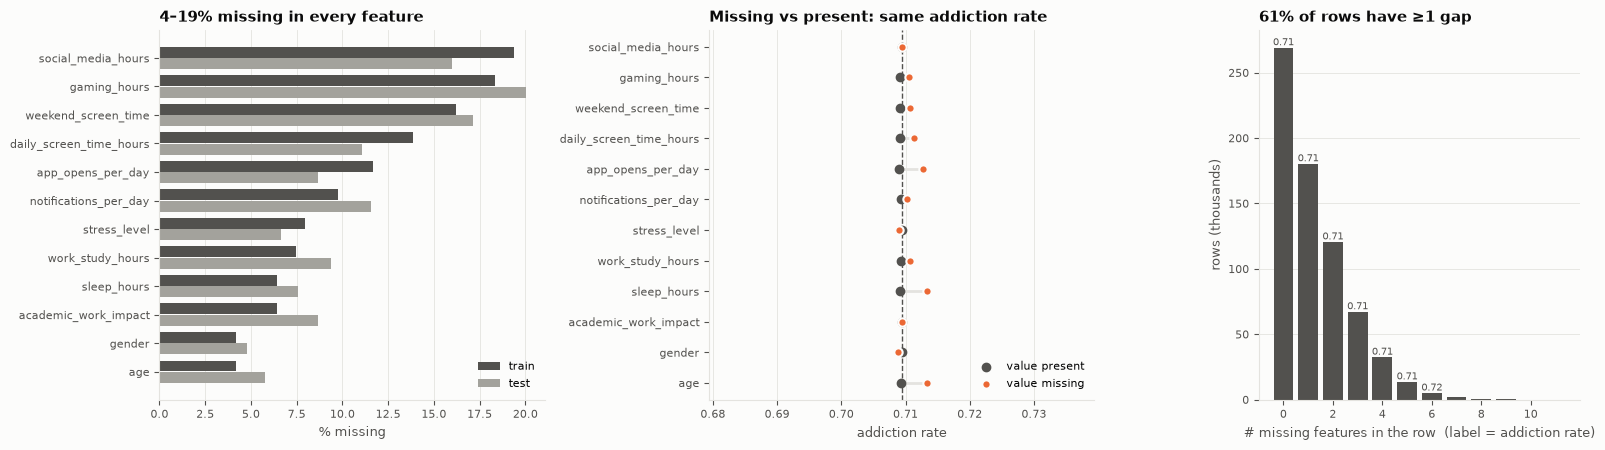

In [9]:
feats = X.columns.tolist()
miss = pd.DataFrame({"train": X.isna().mean(), "test": test_data[feats].isna().mean()}).sort_values("train")
rate_missing = pd.Series({c: y[X[c].isna()].mean() for c in feats})
rate_present = pd.Series({c: y[X[c].notna()].mean() for c in feats})
n_missing = X.isna().sum(axis=1)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1.2, 1.2, 1]})

ax = axes[0]
pos = np.arange(len(miss))
ax.barh(pos + 0.2, miss.train * 100, height=0.38, color="#52514e", label="train")
ax.barh(pos - 0.2, miss.test * 100, height=0.38, color="#a3a29c", label="test")
ax.set_yticks(pos, miss.index)
ax.set_xlabel("% missing")
ax.set_title("4–19% missing in every feature", loc="left")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)

ax = axes[1]
order = miss.index
ax.hlines(pos, rate_present[order], rate_missing[order], color=GRID, lw=2)
ax.scatter(rate_present[order], pos, color=INK2, s=36, label="value present", zorder=3)
ax.scatter(rate_missing[order], pos, color=C1, s=36, label="value missing", zorder=3, edgecolor="#fcfcfb", lw=1.5)
prior_line(ax, "v")
ax.set_yticks(pos, order)
ax.set_xlim(prior - 0.03, prior + 0.03)
ax.set_xlabel("addiction rate")
ax.set_title("Missing vs present: same addiction rate", loc="left")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)

ax = axes[2]
nm = n_missing.value_counts().sort_index()
ax.bar(nm.index, nm.values / 1e3, color=INK2, width=0.8)
ax2_rate = y.groupby(n_missing).mean()
for k, v in nm.items():
    if v > 3000:
        ax.text(k, v / 1e3, f"{ax2_rate[k]:.2f}", ha="center", va="bottom", fontsize=7, color=INK2)
ax.set_xlabel("# missing features in the row  (label = addiction rate)")
ax.set_ylabel("rows (thousands)")
ax.set_title("61% of rows have ≥1 gap", loc="left")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

> **Takeaway: missing values.**
> * Every feature has gaps, and **61% of rows have at least one**. Dropping incomplete rows would discard most of the data.
> * The addiction rate is the same (≈0.71) whether a value is missing or present, for every feature and for any number of
>   missing values per row. The values look **missing completely at random**, so missing-indicator or `n_missing` features would only add noise.
> * Train and test have similar missing rates, so no special handling is needed for the test set.
> * **Action:** let the GBM (LightGBM / XGBoost / CatBoost) handle NaN natively. For linear or NN models, impute from the
>   correlated screen-time features (section 2.6) rather than with the column median.

### 2.3 Numeric features: distribution by class

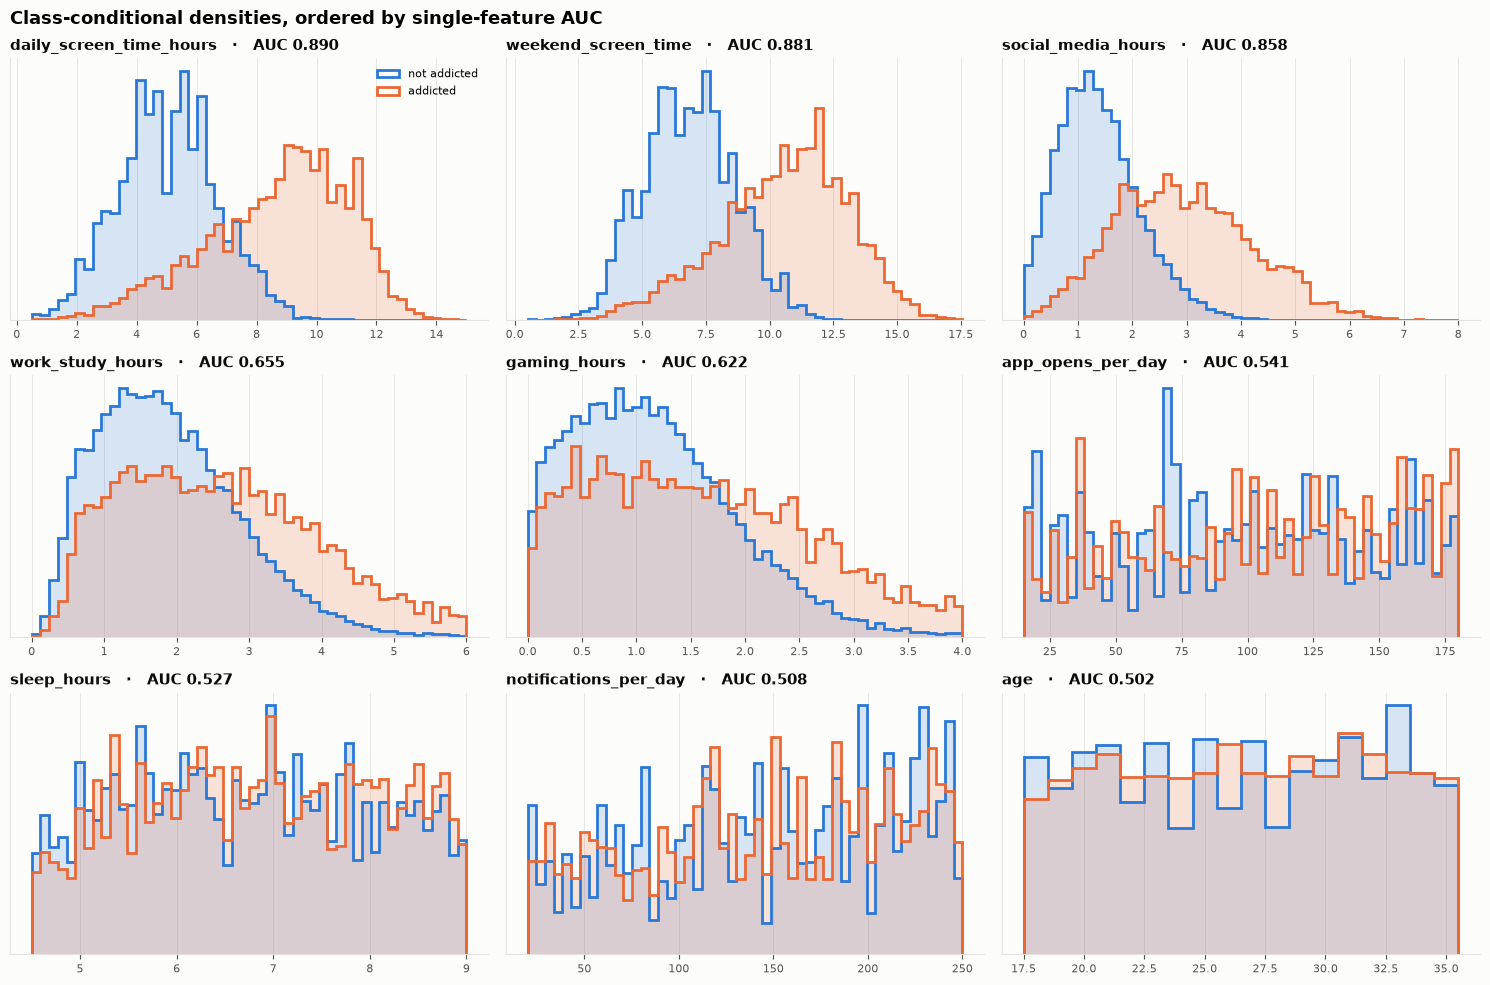

In [10]:
auc = {}
for c in num_cols:
    m = X[c].notna()
    a = roc_auc_score(y[m], X.loc[m, c])
    auc[c] = max(a, 1 - a)
order_num = sorted(num_cols, key=lambda c: -auc[c])

fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, c in zip(axes.flat, order_num):
    bins = np.arange(X[c].min() - 0.5, X[c].max() + 1) if c == "age" else np.histogram_bin_edges(X[c].dropna(), bins=50)
    for lbl, col, name in [(0, C0, "not addicted"), (1, C1, "addicted")]:
        v = X.loc[y == lbl, c].dropna()
        ax.hist(v, bins=bins, density=True, histtype="stepfilled", color=col, alpha=0.18)
        ax.hist(v, bins=bins, density=True, histtype="step", color=col, lw=2, label=name)
    ax.set_title(f"{c}   ·   AUC {auc[c]:.3f}", loc="left")
    ax.set_yticks([])
    ax.grid(axis="y", visible=False)
axes.flat[0].legend(loc="upper right")
fig.suptitle("Class-conditional densities, ordered by single-feature AUC", x=0.01, ha="left", fontsize=13, weight="bold")
plt.tight_layout(); plt.show()

> **Takeaway: distributions.**
> * **Strong separators:** `daily_screen_time_hours` (AUC 0.89), `weekend_screen_time` (0.88) and `social_media_hours` (0.86).
>   Most addicted users are above about 7 h/day of screen time and 2.5 h/day of social media.
> * **Weak:** `work_study_hours` and `gaming_hours` (≈0.62–0.65). They only matter in the upper tail.
> * **Apparently useless:** `age`, `sleep_hours`, `notifications_per_day` and `app_opens_per_day` have almost identical
>   class shapes (AUC ≈ 0.50–0.54). The next plot shows this is misleading.
> * No feature needs a log transform or outlier clipping: all are bounded (e.g. screen time 0.5–15 h, notifications 20–250).

### 2.4 Addiction rate per value: the trend vs exact values
The line is the addiction rate in 20 quantile bins, which shows the smooth trend.
Each grey dot is the rate for one **exact value** (values with ≥ 200 rows).
If a feature carried no information beyond its trend, the dots would sit on the line.

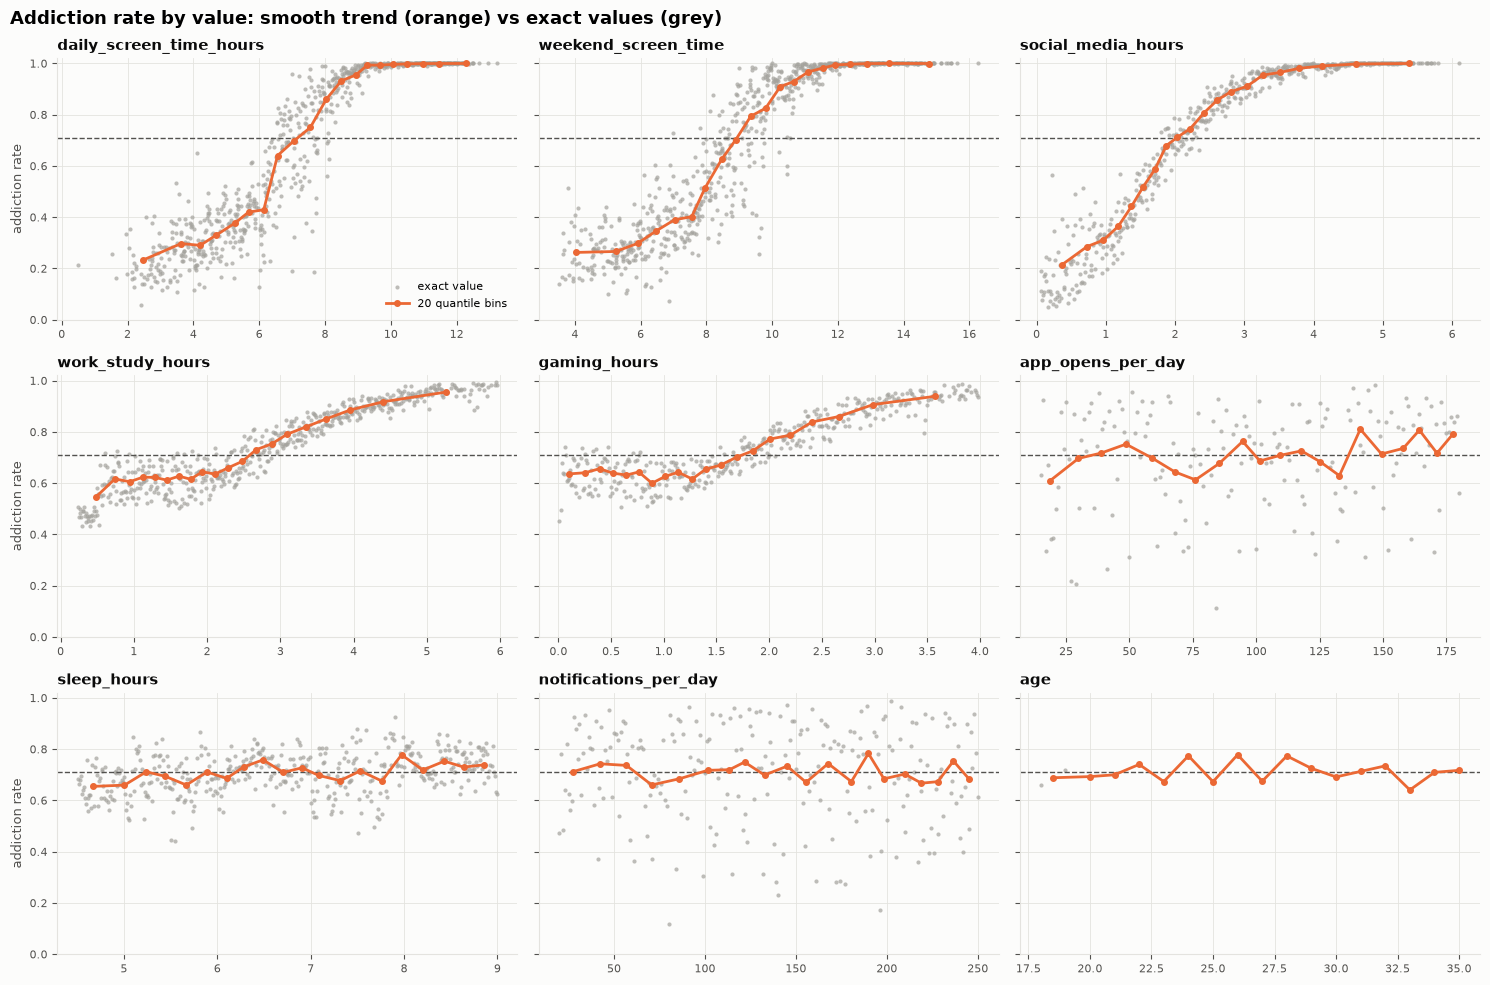

In [11]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10), sharey=True)
for ax, c in zip(axes.flat, order_num):
    per_val = y.groupby(X[c]).agg(["mean", "size"])
    per_val = per_val[per_val["size"] >= 200]
    ax.scatter(per_val.index, per_val["mean"], s=9, color=MUTED, alpha=0.7, lw=0, label="exact value")
    bins = pd.qcut(X[c], 20, duplicates="drop")
    binned = pd.DataFrame({"x": X[c], "y": y}).groupby(bins, observed=True).mean()
    ax.plot(binned.x, binned.y, color=C1, marker="o", ms=4, label="20 quantile bins")
    prior_line(ax)
    ax.set_title(c, loc="left")
    ax.set_ylim(0, 1.02)
axes.flat[0].legend(loc="lower right")
for ax in axes[:, 0]:
    ax.set_ylabel("addiction rate")
fig.suptitle("Addiction rate by value: smooth trend (orange) vs exact values (grey)", x=0.01, ha="left", fontsize=13, weight="bold")
plt.tight_layout(); plt.show()

> **Takeaway: exact values are a hidden signal (the most important finding).**
> * For `notifications_per_day`, `app_opens_per_day`, `sleep_hours` and `age` the binned trend is **flat**,
>   but individual exact values have addiction rates from about **0.1 to 0.99** (e.g. `notifications_per_day == 80` → 12%,
>   `== 202` → 99%; `app_opens_per_day == 84` → 11%, `== 147` → 99%). Each value has thousands of rows, so this is not noise.
>   It is typical of Playground synthetic data: specific values are copied from the original dataset along with their labels.
> * `age` shows a similar odd/even zig-zag (24, 26, 28 → ≈0.77; 23, 25, 27 → ≈0.67).
> * **Action:** treat these columns as **categorical as well as numeric**. Add out-of-fold **target encoding**
>   (or frequency encoding) of the exact value, or pass them as `category` dtype to LightGBM/CatBoost.
>   Every test value also appears in train, so the encoding fully covers the test set.
> * The screen-time features also have extra scatter around their trend, so target-encoding them may help a little as well.

### 2.5 Signal summary: numeric AUC vs out-of-fold target-encoded AUC

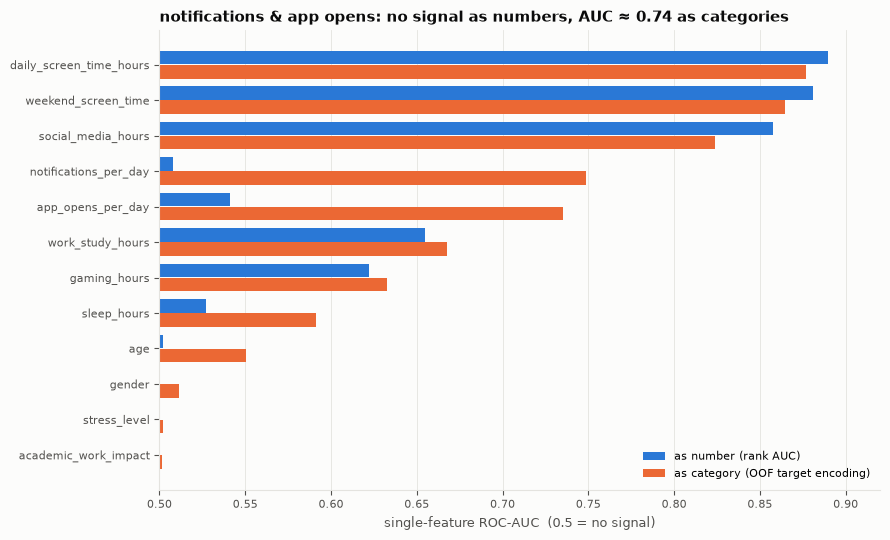

,as number,as category (OOF target enc.)
academic_work_impact,NaN,0.501
stress_level,NaN,0.502
gender,NaN,0.511
age,0.502,0.550
sleep_hours,0.527,0.591
gaming_hours,0.622,0.633
work_study_hours,0.655,0.667
app_opens_per_day,0.541,0.735
notifications_per_day,0.508,0.749
social_media_hours,0.858,0.824


In [12]:
def oof_target_encode(col, y, n_splits=5, smoothing=20, seed=0):
    """Out-of-fold smoothed mean-target encoding of a column's exact values."""
    x = col.astype(str).values
    yv = y.values
    out = np.empty(len(col))
    for tr_idx, va_idx in StratifiedKFold(n_splits, shuffle=True, random_state=seed).split(x, yv):
        stats = pd.DataFrame({"x": x[tr_idx], "y": yv[tr_idx]}).groupby("x")["y"].agg(["sum", "count"])
        enc = (stats["sum"] + smoothing * prior) / (stats["count"] + smoothing)
        out[va_idx] = pd.Series(x[va_idx]).map(enc).fillna(prior).values
    return out

te_auc = {c: roc_auc_score(y, oof_target_encode(X[c], y)) for c in X.columns}
summary = pd.DataFrame({"as number": pd.Series(auc), "as category (OOF target enc.)": pd.Series(te_auc)})
summary = summary.loc[summary.max(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(9, 5.5))
pos = np.arange(len(summary))
ax.barh(pos + 0.2, summary["as number"].fillna(0.5) - 0.5, left=0.5, height=0.38, color=C0, label="as number (rank AUC)")
ax.barh(pos - 0.2, summary["as category (OOF target enc.)"] - 0.5, left=0.5, height=0.38, color=C1, label="as category (OOF target encoding)")
ax.set_yticks(pos, summary.index)
ax.set_xlim(0.5, 0.92)
ax.set_xlabel("single-feature ROC-AUC  (0.5 = no signal)")
ax.set_title("notifications & app opens: no signal as numbers, AUC ≈ 0.74 as categories", loc="left")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
summary.round(3)

> **Takeaway: feature priority.**
> * **Tier 1:** `daily_screen_time_hours`, `weekend_screen_time`, `social_media_hours`.
> * **Tier 2:** `notifications_per_day`, `app_opens_per_day`. These are useful **only when encoded as categories**.
> * **Tier 3:** `work_study_hours`, `gaming_hours`, `sleep_hours` (as a category), `age` (as a category).
> * **Noise:** `gender`, `stress_level`, `academic_work_impact`. Try dropping them, and keep them only if CV improves.

### 2.6 Categorical features

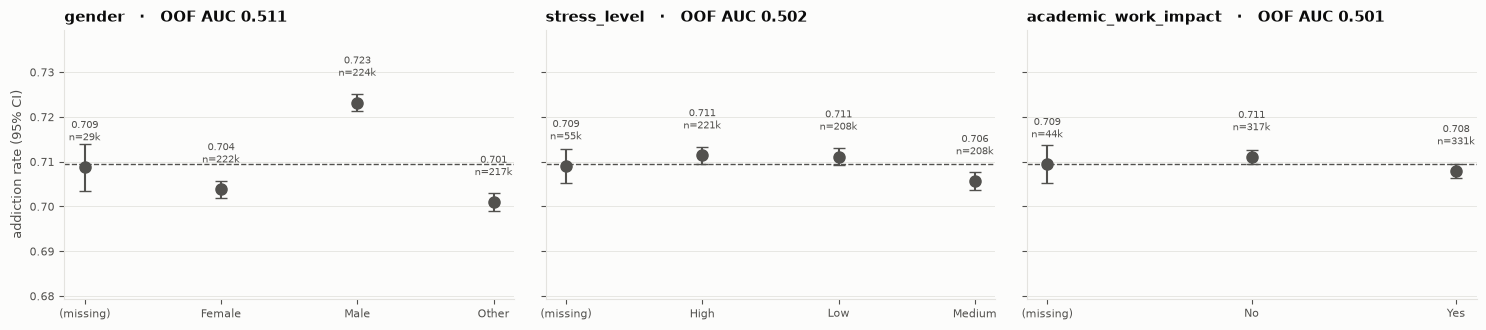

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.4), sharey=True)
for ax, c in zip(axes, cat_cols):
    g = y.groupby(X[c].fillna("(missing)")).agg(["mean", "size"])
    ci = 1.96 * np.sqrt(g["mean"] * (1 - g["mean"]) / g["size"])
    ax.errorbar(g.index, g["mean"], yerr=ci, fmt="o", color=INK2, ms=8, capsize=4, lw=1.5)
    for i, (k, r) in enumerate(g.iterrows()):
        ax.text(i, r["mean"] + 0.006, f"{r['mean']:.3f}\nn={r['size']/1e3:.0f}k", ha="center", fontsize=7, color=INK2)
    prior_line(ax)
    ax.set_title(f"{c}   ·   OOF AUC {te_auc[c]:.3f}", loc="left")
    ax.set_ylim(prior - 0.03, prior + 0.03)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("addiction rate (95% CI)")
plt.tight_layout(); plt.show()

> **Takeaway: categoricals.** The addiction rate varies by at most about 2 percentage points across categories.
> The only statistically visible effect is `gender = Male` (+1.4 pp), and even that adds almost nothing (AUC 0.51).
> `stress_level` and `academic_work_impact` are flat. They do not even correlate with screen time (mean screen time is ≈7.6 h at every stress level).
> **Action:** one-hot or native categorical encoding is enough. These are the first candidates to drop if they add CV noise.

### 2.7 Feature-to-feature relationships

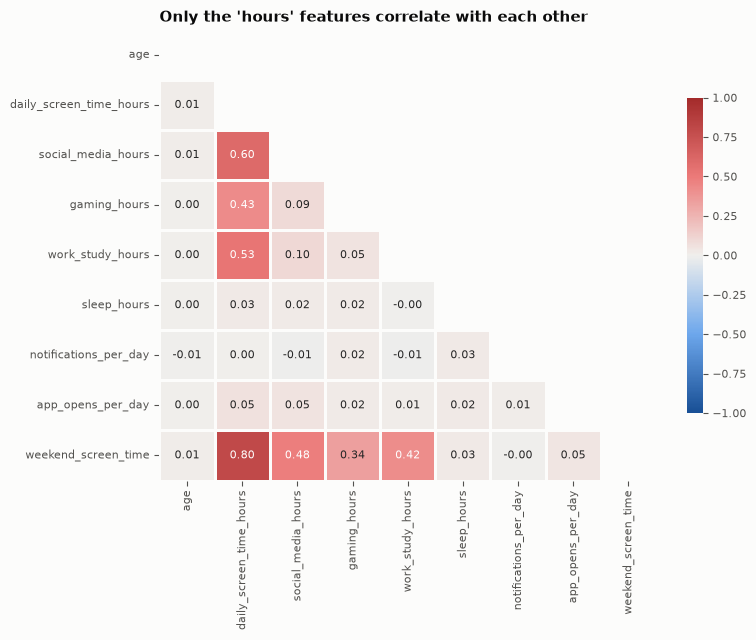

In [14]:
corr = X[num_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, mask=mask, cmap=DIVERGING, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"size": 8}, linewidths=2, linecolor="#fcfcfb", cbar_kws={"shrink": 0.7}, ax=ax)
ax.grid(False)
ax.set_title("Only the 'hours' features correlate with each other", loc="left")
plt.tight_layout(); plt.show()

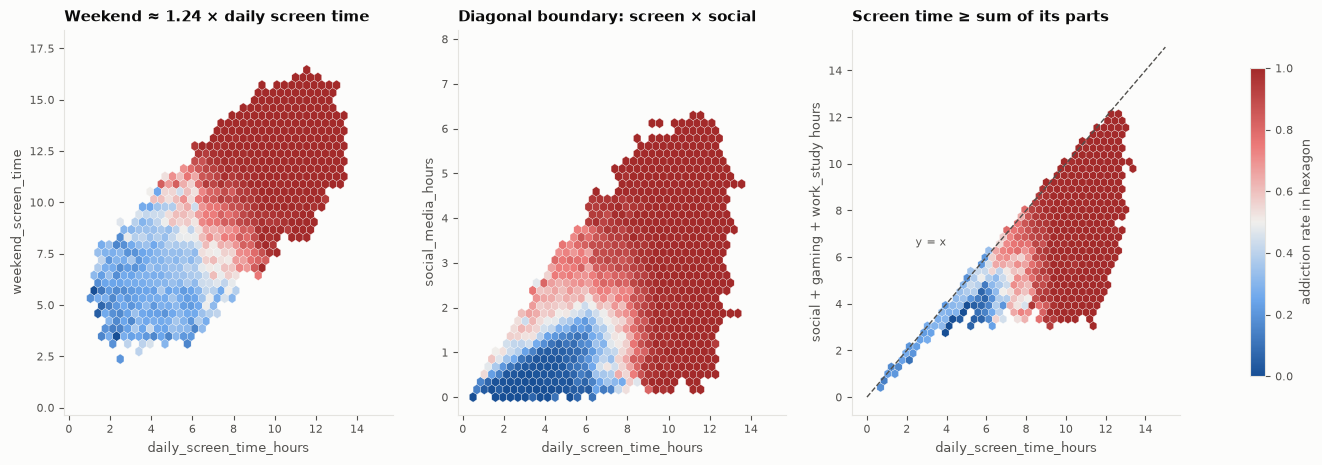

In [15]:
sample = train_data.sample(150_000, random_state=0)
parts = sample[["social_media_hours", "gaming_hours", "work_study_hours"]].sum(axis=1, min_count=3)
pairs = [
    ("daily_screen_time_hours", sample["weekend_screen_time"], "weekend_screen_time"),
    ("daily_screen_time_hours", sample["social_media_hours"], "social_media_hours"),
    ("daily_screen_time_hours", parts, "social + gaming + work_study hours"),
]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (xc, yv, ylab) in zip(axes, pairs):
    ok = sample[xc].notna() & yv.notna()
    hb = ax.hexbin(sample.loc[ok, xc], yv[ok], C=sample.loc[ok, TARGET], reduce_C_function=np.mean, gridsize=40,
                   cmap=DIVERGING, vmin=0, vmax=1, mincnt=15, linewidths=0.2, edgecolors="#fcfcfb")
    ax.set_xlabel(xc); ax.set_ylabel(ylab)
    ax.grid(False)
lim = [0, 15]
axes[2].plot(lim, lim, color=INK2, ls="--", lw=1)
axes[2].text(4, 6.5, "y = x", ha="right", color=INK2, fontsize=8)
axes[0].set_title("Weekend ≈ 1.24 × daily screen time", loc="left")
axes[1].set_title("Diagonal boundary: screen × social", loc="left")
axes[2].set_title("Screen time ≥ sum of its parts", loc="left")
fig.colorbar(hb, ax=axes, shrink=0.8, label="addiction rate in hexagon")
plt.show()

> **Takeaway: relationships.**
> * `daily_screen_time_hours` ↔ `weekend_screen_time` (r = 0.80). Weekend time is about 1.24× weekday time (median ratio).
>   **Action:** when one of them is missing (14–16% of rows), impute it from the other. This recovers the strongest
>   feature for many rows. GBMs partly do this already through the other column.
> * Screen time almost always exceeds `social + gaming + work_study` (median gap 0.75 h, r = 0.84).
>   **Action:** add engineered features: `other_hours = screen − (social + gaming + work)`, the shares
>   `social_media_hours / screen`, `gaming_hours / screen` and `work_study_hours / screen`, and `weekend − daily`.
>   Also use the sum of parts as a fallback when screen time is missing.
> * The decision boundary in the middle plot is diagonal: addiction depends on **screen time and social media together**.
>   Tree models need many splits to approximate a diagonal, so a ratio or sum feature should make them more efficient.
> * Age, sleep, notifications and app opens are uncorrelated with everything (|r| ≤ 0.05). Their signal is
>   independent, so they need the categorical encoding from section 2.4.

### 2.8 Train vs test drift check

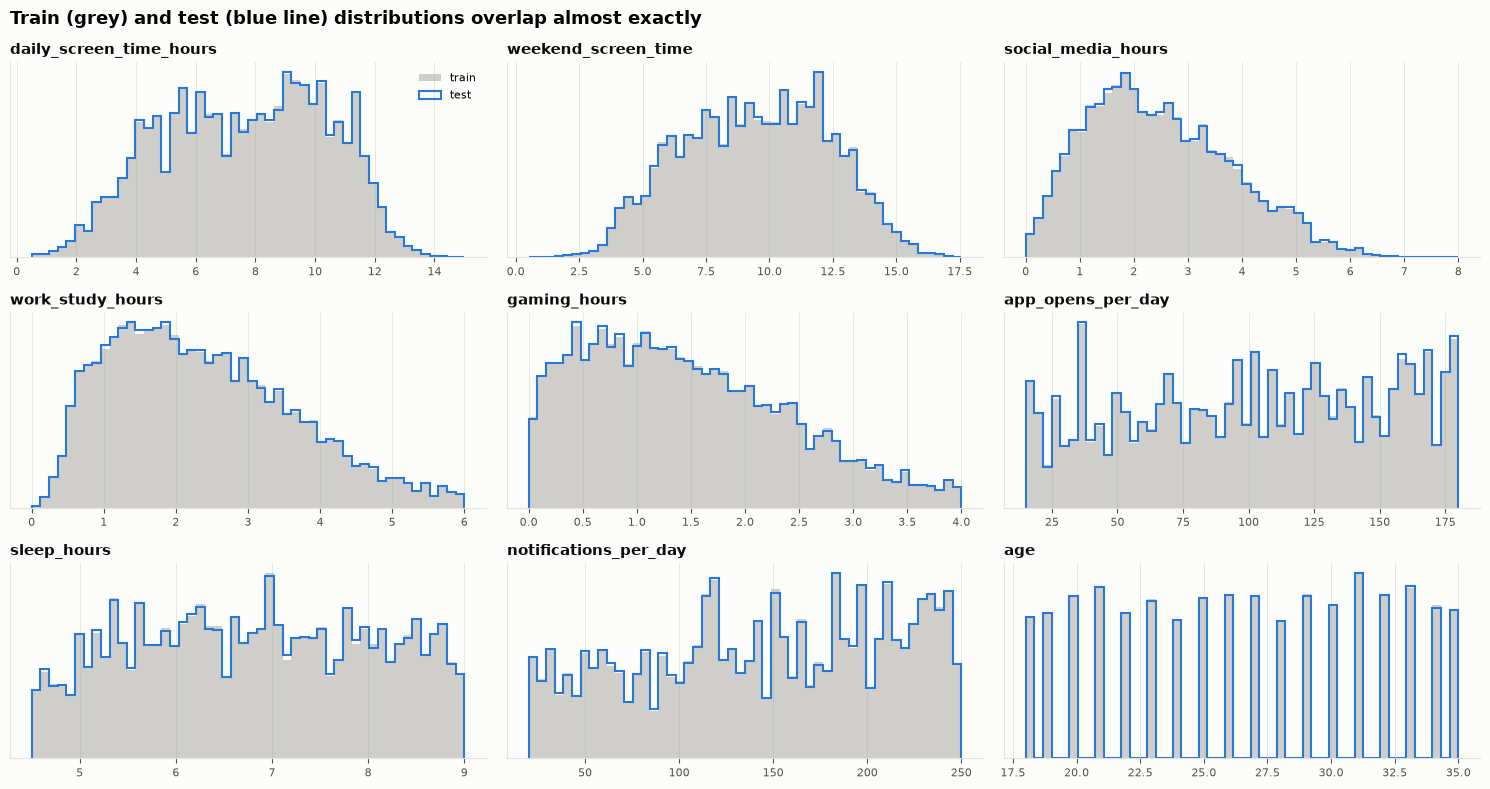

In [16]:
fig, axes = plt.subplots(3, 3, figsize=(15, 8))
for ax, c in zip(axes.flat, order_num):
    bins = np.histogram_bin_edges(X[c].dropna(), bins=50)
    ax.hist(X[c].dropna(), bins=bins, density=True, histtype="stepfilled", color=MUTED, alpha=0.5, label="train")
    ax.hist(test_data[c].dropna(), bins=bins, density=True, histtype="step", color=C0, lw=1.5, label="test")
    ax.set_title(c, loc="left"); ax.set_yticks([]); ax.grid(axis="y", visible=False)
axes.flat[0].legend()
fig.suptitle("Train (grey) and test (blue line) distributions overlap almost exactly", x=0.01, ha="left", fontsize=13, weight="bold")
plt.tight_layout(); plt.show()

> **Takeaway: drift.** Train and test match on every feature (means agree within 0.1%) and have similar
> missing rates. **Local CV should track the leaderboard**, so trust CV over public-LB noise.
> No adversarial validation or reweighting is needed.

### 2.9 Quick check: do the EDA conclusions improve a model?
Same HistGradientBoosting model on a 200k-row sample, 5-fold stratified CV:
raw features vs raw + out-of-fold target encodings of the "exact value" features + the engineered hour features.

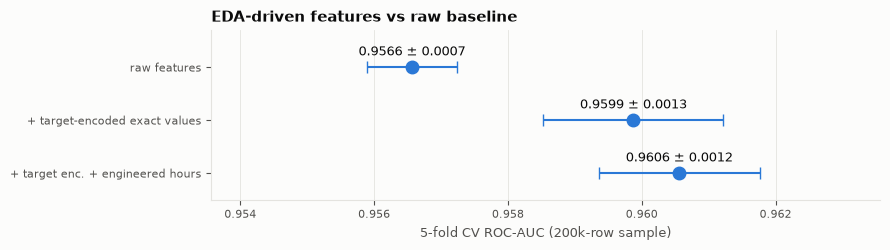

In [17]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import cross_val_score

def add_features(df):
    df = df.copy()
    parts = df[["social_media_hours", "gaming_hours", "work_study_hours"]].sum(axis=1, min_count=3)
    screen = df["daily_screen_time_hours"].fillna(df["weekend_screen_time"] / 1.24)
    df["screen_filled"] = screen
    df["other_hours"] = screen - parts
    df["social_share"] = df["social_media_hours"] / screen
    df["weekend_minus_daily"] = df["weekend_screen_time"] - df["daily_screen_time_hours"]
    return df

sample = train_data.sample(200_000, random_state=1)
ys = sample[TARGET]
Xs = sample.drop(columns=TARGET)
for c in cat_cols:
    Xs[c] = Xs[c].astype("category")

te_cols = ["notifications_per_day", "app_opens_per_day", "sleep_hours", "age"]
# Target encoding is fit inside each CV fold to avoid leakage
from sklearn.base import BaseEstimator, ClassifierMixin, clone

class TEThenGBM(ClassifierMixin, BaseEstimator):
    def __init__(self, cols, engineer=False):
        self.cols, self.engineer = cols, engineer
    def _transform(self, Xd):
        Xd = add_features(Xd) if self.engineer else Xd.copy()
        for c in self.cols:
            Xd[f"te_{c}"] = Xd[c].astype(str).map(self.maps_[c]).astype(float).fillna(self.prior_)
        return Xd
    def fit(self, Xd, yd):
        self.classes_ = np.unique(yd)
        self.prior_ = yd.mean()
        self.maps_ = {}
        Xtr = Xd.copy()
        for c in self.cols:   # in-fold OOF encoding for the training rows, full-fold map for scoring
            Xtr[f"te_{c}"] = oof_target_encode(Xd[c], yd, seed=2)
            s = yd.groupby(Xd[c].astype(str)).agg(["sum", "count"])
            self.maps_[c] = (s["sum"] + 20 * self.prior_) / (s["count"] + 20)
        if self.engineer:
            Xtr = pd.concat([add_features(Xd), Xtr[[f"te_{c}" for c in self.cols]]], axis=1)
        self.model_ = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08,
                                                     categorical_features="from_dtype", random_state=0)
        self.model_.fit(Xtr, yd)
        return self
    def predict_proba(self, Xd):
        return self.model_.predict_proba(self._transform(Xd))

cv = StratifiedKFold(5, shuffle=True, random_state=0)
variants = {
    "raw features": TEThenGBM(cols=[]),
    "+ target-encoded exact values": TEThenGBM(cols=te_cols),
    "+ target enc. + engineered hours": TEThenGBM(cols=te_cols, engineer=True),
}
scores = {k: cross_val_score(m, Xs, ys, cv=cv, scoring="roc_auc") for k, m in variants.items()}

fig, ax = plt.subplots(figsize=(9, 2.6))
names = list(scores)[::-1]
means = [scores[k].mean() for k in names]
stds = [scores[k].std() for k in names]
# dot plot (not bars) because the axis is zoomed in on a narrow AUC range
ax.errorbar(means, names, xerr=stds, fmt="o", color=C0, ms=9, capsize=4, lw=1.5)
for i, k in enumerate(names):
    ax.text(means[i], i + 0.22, f"{means[i]:.4f} ± {stds[i]:.4f}", ha="center", fontsize=9, color=INK)
ax.set_ylim(-0.5, len(names) - 0.3)
ax.set_xlim(min(means) - 0.003, max(means) + 0.003)
ax.set_xlabel("5-fold CV ROC-AUC (200k-row sample)")
ax.set_title("EDA-driven features vs raw baseline", loc="left")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

> **Takeaway: the conclusions hold up.** On the same model and folds, adding out-of-fold target encodings of the exact values
> (`notifications_per_day`, `app_opens_per_day`, `sleep_hours`, `age`) raises CV AUC from **0.9566 to 0.9599**. Adding the engineered
> hour features brings it to **0.9606**. Both gains are several fold-standard-deviations wide. This is a 200k-row sample;
> expect a somewhat higher absolute AUC on the full 691k rows.

---
## 3. Actionable conclusions

| # | Finding (evidence) | Action |
|---|---|---|
| 1 | Target is 71% positive; the submission is a probability (2.1) | Optimise ROC-AUC with StratifiedKFold; no resampling |
| 2 | Missingness is random: the addiction rate is the same with or without the value (2.2) | Keep NaN for the GBMs; skip missing-indicator features |
| 3 | Screen time, weekend screen time and social media hours dominate, with AUC 0.86–0.89 each (2.3, 2.5) | Core features; build interactions around them |
| 4 | **Exact values** of notifications, app opens, sleep and age carry strong label signal, while their numeric trend is flat (2.4, 2.5) | Add **OOF target encoding / categorical versions** of these columns (+0.003 AUC measured in 2.9, the biggest gain) |
| 5 | Screen time ≈ weekend / 1.24 and ≥ sum of social + gaming + work (2.7) | Impute screen time from the other columns; add `other_hours`, share and difference features |
| 6 | The boundary is diagonal in screen time × social media (2.7) | Ratio and sum features; consider a monotone constraint on screen time and social media hours |
| 7 | Gender, stress and academic impact are near-noise, with AUC ≤ 0.51 (2.6) | Test dropping them in CV |
| 8 | Train and test are identically distributed (2.8) | Trust local CV; no adversarial validation needed |

**Next step:** a LightGBM / CatBoost model on the full data with conclusions 4 and 5, tuned on 5-fold CV.
Then ensemble with a model that treats every numeric column purely as a category (CatBoost with `cat_features` on all columns).